## Random Forest

### 1. Import libraries

In [37]:
import glob

import numpy as np
import pandas as pandas
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

#### 2. Data preprocessing

##### 2a. Import CSV files and combine into one dataframe

In [2]:
csv_folder = "../data/loose_csv/*.csv"
file_paths = glob.glob(csv_folder)

print(f"Found {len(file_paths)} files")

dataframe_list = [pandas.read_csv(file) for file in file_paths]
dataframe_combined = pandas.concat(dataframe_list, ignore_index=True)
dataframe_combined = dataframe_combined.reset_index(drop=True)

Found 15 files


##### 2b. Overview of data

In [3]:
dataframe_combined.shape

(3385313, 85)

In [ ]:
dataframe_combined.head()

In [4]:
dataframe_combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 3385313 entries, 0 to 3385312
Data columns (total 85 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   Flow ID                     str    
 1   Src IP                      str    
 2   Src Port                    int64  
 3   Dst IP                      str    
 4   Dst Port                    int64  
 5   Protocol                    int64  
 6   Timestamp                   str    
 7   Flow Duration               int64  
 8   Total Fwd Packet            int64  
 9   Total Bwd packets           int64  
 10  Total Length of Fwd Packet  float64
 11  Total Length of Bwd Packet  float64
 12  Fwd Packet Length Max       float64
 13  Fwd Packet Length Min       float64
 14  Fwd Packet Length Mean      float64
 15  Fwd Packet Length Std       float64
 16  Bwd Packet Length Max       float64
 17  Bwd Packet Length Min       float64
 18  Bwd Packet Length Mean      float64
 19  Bwd Packet Length Std       floa

In [ ]:
dataframe_combined["Attack Name"].value_counts()

##### 2c. Replace spaces in columns with "_"

In [5]:
dataframe_combined.columns = dataframe_combined.columns.str.replace(" ", "_")
dataframe_combined.columns.to_list()

['Flow_ID',
 'Src_IP',
 'Src_Port',
 'Dst_IP',
 'Dst_Port',
 'Protocol',
 'Timestamp',
 'Flow_Duration',
 'Total_Fwd_Packet',
 'Total_Bwd_packets',
 'Total_Length_of_Fwd_Packet',
 'Total_Length_of_Bwd_Packet',
 'Fwd_Packet_Length_Max',
 'Fwd_Packet_Length_Min',
 'Fwd_Packet_Length_Mean',
 'Fwd_Packet_Length_Std',
 'Bwd_Packet_Length_Max',
 'Bwd_Packet_Length_Min',
 'Bwd_Packet_Length_Mean',
 'Bwd_Packet_Length_Std',
 'Flow_Bytes/s',
 'Flow_Packets/s',
 'Flow_IAT_Mean',
 'Flow_IAT_Std',
 'Flow_IAT_Max',
 'Flow_IAT_Min',
 'Fwd_IAT_Total',
 'Fwd_IAT_Mean',
 'Fwd_IAT_Std',
 'Fwd_IAT_Max',
 'Fwd_IAT_Min',
 'Bwd_IAT_Total',
 'Bwd_IAT_Mean',
 'Bwd_IAT_Std',
 'Bwd_IAT_Max',
 'Bwd_IAT_Min',
 'Fwd_PSH_Flags',
 'Bwd_PSH_Flags',
 'Fwd_URG_Flags',
 'Bwd_URG_Flags',
 'Fwd_Header_Length',
 'Bwd_Header_Length',
 'Fwd_Packets/s',
 'Bwd_Packets/s',
 'Packet_Length_Min',
 'Packet_Length_Max',
 'Packet_Length_Mean',
 'Packet_Length_Std',
 'Packet_Length_Variance',
 'FIN_Flag_Count',
 'SYN_Flag_Count',
 'R

##### 2d. Drop unimportant columns

In [6]:
dataframe_combined = dataframe_combined.drop(columns=["Flow_ID", "Src_IP", "Src_Port", "Dst_IP", "Dst_Port", "Protocol", "Timestamp"])
dataframe_combined.columns.to_list()

['Flow_Duration',
 'Total_Fwd_Packet',
 'Total_Bwd_packets',
 'Total_Length_of_Fwd_Packet',
 'Total_Length_of_Bwd_Packet',
 'Fwd_Packet_Length_Max',
 'Fwd_Packet_Length_Min',
 'Fwd_Packet_Length_Mean',
 'Fwd_Packet_Length_Std',
 'Bwd_Packet_Length_Max',
 'Bwd_Packet_Length_Min',
 'Bwd_Packet_Length_Mean',
 'Bwd_Packet_Length_Std',
 'Flow_Bytes/s',
 'Flow_Packets/s',
 'Flow_IAT_Mean',
 'Flow_IAT_Std',
 'Flow_IAT_Max',
 'Flow_IAT_Min',
 'Fwd_IAT_Total',
 'Fwd_IAT_Mean',
 'Fwd_IAT_Std',
 'Fwd_IAT_Max',
 'Fwd_IAT_Min',
 'Bwd_IAT_Total',
 'Bwd_IAT_Mean',
 'Bwd_IAT_Std',
 'Bwd_IAT_Max',
 'Bwd_IAT_Min',
 'Fwd_PSH_Flags',
 'Bwd_PSH_Flags',
 'Fwd_URG_Flags',
 'Bwd_URG_Flags',
 'Fwd_Header_Length',
 'Bwd_Header_Length',
 'Fwd_Packets/s',
 'Bwd_Packets/s',
 'Packet_Length_Min',
 'Packet_Length_Max',
 'Packet_Length_Mean',
 'Packet_Length_Std',
 'Packet_Length_Variance',
 'FIN_Flag_Count',
 'SYN_Flag_Count',
 'RST_Flag_Count',
 'PSH_Flag_Count',
 'ACK_Flag_Count',
 'URG_Flag_Count',
 'CWR_Flag_Cou

##### 2e. Change 'Label' column type to bool

In [7]:
dataframe_combined["Label"] = dataframe_combined["Label"].astype(bool)
dataframe_combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 3385313 entries, 0 to 3385312
Data columns (total 78 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   Flow_Duration               int64  
 1   Total_Fwd_Packet            int64  
 2   Total_Bwd_packets           int64  
 3   Total_Length_of_Fwd_Packet  float64
 4   Total_Length_of_Bwd_Packet  float64
 5   Fwd_Packet_Length_Max       float64
 6   Fwd_Packet_Length_Min       float64
 7   Fwd_Packet_Length_Mean      float64
 8   Fwd_Packet_Length_Std       float64
 9   Bwd_Packet_Length_Max       float64
 10  Bwd_Packet_Length_Min       float64
 11  Bwd_Packet_Length_Mean      float64
 12  Bwd_Packet_Length_Std       float64
 13  Flow_Bytes/s                float64
 14  Flow_Packets/s              float64
 15  Flow_IAT_Mean               float64
 16  Flow_IAT_Std                float64
 17  Flow_IAT_Max                float64
 18  Flow_IAT_Min                float64
 19  Fwd_IAT_Total               floa

##### 2f. Drop rows with null values (currently unnecessary as no rows have null values)

In [8]:
dataframe_combined.dropna()

,Flow_Duration,Total_Fwd_Packet,Total_Bwd_packets,Total_Length_of_Fwd_Packet,Total_Length_of_Bwd_Packet,Fwd_Packet_Length_Max,Fwd_Packet_Length_Min,Fwd_Packet_Length_Mean,Fwd_Packet_Length_Std,Bwd_Packet_Length_Max,...,Active_Mean,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min,Attack_Name,Label
0,14746364,6,0,63.0,0.0,39.0,0.0,10.500000,16.944025,0.0,...,0.0,0.0,0.0,0.0,14681116.0,0.000000,14681116.0,14681116.0,Benign Traffic,False
1,60102110,18,0,4135.0,0.0,1408.0,0.0,229.722222,490.460505,0.0,...,219123.0,0.0,219123.0,219123.0,14957706.0,190543.248665,15061923.0,14672051.0,Benign Traffic,False
2,90106769,9,0,1164.0,0.0,194.0,0.0,129.333333,97.000000,0.0,...,582529.0,0.0,582529.0,582529.0,29841412.0,319090.538141,30049066.0,29473997.0,Benign Traffic,False
3,119998980,123,123,2157.0,4.0,20.0,0.0,17.536585,2.309257,2.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic,False
4,119998539,123,123,5411.0,4.0,46.0,0.0,43.991870,5.699433,2.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3385308,0,2,0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,MQTT DDoS Publish Flood,True
3385309,1552,2,0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,MQTT DDoS Publish Flood,True
3385310,22717,2,0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,MQTT DDoS Publish Flood,True
3385311,0,2,0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,MQTT DDoS Publish Flood,True


### 3. Prepare data for model training

##### 3a. Sample smaller subset

In [9]:
def sample_or_take_all(group):
    sample_size = min(len(group), 3000)
    return group.sample(n=sample_size, random_state=42)

small_df = dataframe_combined.groupby('Attack_Name').apply(sample_or_take_all)
small_df = small_df.reset_index(level=0)

In [10]:
small_df.info()

<class 'pandas.DataFrame'>
Index: 35558 entries, 6528 to 2731413
Data columns (total 78 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Attack_Name                 35558 non-null  str    
 1   Flow_Duration               35558 non-null  int64  
 2   Total_Fwd_Packet            35558 non-null  int64  
 3   Total_Bwd_packets           35558 non-null  int64  
 4   Total_Length_of_Fwd_Packet  35558 non-null  float64
 5   Total_Length_of_Bwd_Packet  35558 non-null  float64
 6   Fwd_Packet_Length_Max       35558 non-null  float64
 7   Fwd_Packet_Length_Min       35558 non-null  float64
 8   Fwd_Packet_Length_Mean      35558 non-null  float64
 9   Fwd_Packet_Length_Std       35558 non-null  float64
 10  Bwd_Packet_Length_Max       35558 non-null  float64
 11  Bwd_Packet_Length_Min       35558 non-null  float64
 12  Bwd_Packet_Length_Mean      35558 non-null  float64
 13  Bwd_Packet_Length_Std       35558 non-null

##### 3b. Shuffle samples

In [11]:
small_df_rnd = small_df.sample(frac=1, random_state=42)
small_df_rnd = small_df_rnd.reset_index(drop=True)

In [12]:
small_df_rnd.info()

<class 'pandas.DataFrame'>
RangeIndex: 35558 entries, 0 to 35557
Data columns (total 78 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Attack_Name                 35558 non-null  str    
 1   Flow_Duration               35558 non-null  int64  
 2   Total_Fwd_Packet            35558 non-null  int64  
 3   Total_Bwd_packets           35558 non-null  int64  
 4   Total_Length_of_Fwd_Packet  35558 non-null  float64
 5   Total_Length_of_Bwd_Packet  35558 non-null  float64
 6   Fwd_Packet_Length_Max       35558 non-null  float64
 7   Fwd_Packet_Length_Min       35558 non-null  float64
 8   Fwd_Packet_Length_Mean      35558 non-null  float64
 9   Fwd_Packet_Length_Std       35558 non-null  float64
 10  Bwd_Packet_Length_Max       35558 non-null  float64
 11  Bwd_Packet_Length_Min       35558 non-null  float64
 12  Bwd_Packet_Length_Mean      35558 non-null  float64
 13  Bwd_Packet_Length_Std       35558 non-null

##### 3c. Separate targets and features

In [13]:
features = small_df_rnd.drop(columns=['Attack_Name'])
targets = small_df_rnd['Attack_Name']

##### 3d. Create scaler pipeline

In [14]:
# scaler = StandardScaler()
# scaler.fit_transform(features)

scaler_pipeline = Pipeline(steps=["scaler", StandardScaler()])

### 4. Split data into training and test

In [15]:
features_train, features_test, targets_train, targets_test = train_test_split(features, targets, test_size=0.2, random_state=12, shuffle=True)

### 5. Model Training - Hold-out Validation

##### 5a. Create helper evaluate functions

In [34]:
def evaluate(model, features_data, targets_data):
    prediction = model.predict(features_data)
    return {
        "Accuracy": accuracy_score(targets_data, prediction),
        "Precision": precision_score(targets_data, prediction, average="weighted", zero_division=0),
        "Recall": recall_score(targets_data, prediction, average="weighted", zero_division=0),
        "F1": f1_score(targets_data, prediction, average="weighted", zero_division=0),
        "F1_macro": f1_score(targets_data, prediction, average="macro", zero_division=0),
    }

def evaluate_class_report(model, features_data, targets_data):
    prediction = model.predict(features_data)

    return classification_report(targets_data, prediction, output_dict=True, zero_division=0)



def plot_confusion_matrix(model, features_data, targets_data, title="Confusion Matrix"):
    prediction = model.predict(features_data)
    cm = confusion_matrix(targets_data, prediction)

    fig, ax = plt.subplots(figsize=(10,10))
    display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)

    display.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical', values_format="d")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return cm

def plot_confusion_matrix_norm(model, features_data, targets_data, title="Confusion Matrix"):
    prediction = model.predict(features_data)
    cm_normalized = confusion_matrix(targets_data, prediction, normalize='true')

    fig, ax = plt.subplots(figsize=(10,10))
    display = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=model.classes_)

    display.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical', values_format=".2f")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return cm_normalized

##### 5b. Split training and validation data

In [17]:
X_train, X_val, Y_train, Y_val = train_test_split(features_train, targets_train, test_size=0.2, random_state=7, shuffle=True)

##### 5c. Create a raw model

In [18]:
model_holdout = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier())
])

##### 5d. Train and evaluate model using fit() and predict()

In [30]:
model_holdout.fit(X_train, Y_train)

holdout_scores = pandas.DataFrame({
    "Train": evaluate(model_holdout, X_train, Y_train),
    "Validation": evaluate(model_holdout, X_val, Y_val),
}).T
holdout_scores

,Accuracy,Precision,Recall,F1,F1_macro
Train,0.973106,0.977600,0.973106,0.972617,0.977823
Validation,0.820387,0.824904,0.820387,0.818805,0.779247


##### 5e. Classification Reports

In [35]:
holdout_report_train = pandas.DataFrame(evaluate_class_report(model_holdout, X_train, Y_train)).T
holdout_report_train

,precision,recall,f1-score,support
Benign Traffic,1.000000,1.000000,1.000000,1932.000000
DDoS ICMP Flood,1.000000,0.997484,0.998741,1590.000000
DDoS UDP Flood,0.999400,0.999400,0.999400,1668.000000
DoS ICMP Flood,0.997694,0.999230,0.998462,1299.000000
DoS TCP Flood,1.000000,1.000000,1.000000,1951.000000
DoS UDP Flood,0.998959,0.995851,0.997403,1928.000000
MITM ARP Spoofing,1.000000,0.998454,0.999227,647.000000
MQTT DDoS Publish Flood,0.997407,0.999480,0.998442,1924.000000
MQTT DoS Connect Flood,0.993229,0.998429,0.995822,1910.000000
MQTT DoS Publish Flood,1.000000,0.998344,0.999171,604.000000


In [36]:
holdout_report_val = pandas.DataFrame(evaluate_class_report(model_holdout, X_val, Y_val)).T
holdout_report_val

,precision,recall,f1-score,support
Benign Traffic,0.995807,1.000000,0.997899,475.000000
DDoS ICMP Flood,0.596741,0.662896,0.628081,442.000000
DDoS UDP Flood,0.542169,0.555556,0.548780,405.000000
DoS ICMP Flood,0.640449,0.624658,0.632455,365.000000
DoS TCP Flood,1.000000,1.000000,1.000000,458.000000
DoS UDP Flood,0.648760,0.670940,0.659664,468.000000
MITM ARP Spoofing,0.608333,0.396739,0.480263,184.000000
MQTT DDoS Publish Flood,0.953191,0.951168,0.952179,471.000000
MQTT DoS Connect Flood,0.942116,0.965235,0.953535,489.000000
MQTT DoS Publish Flood,0.907801,0.927536,0.917563,138.000000


##### 5e. Confusion Matrices

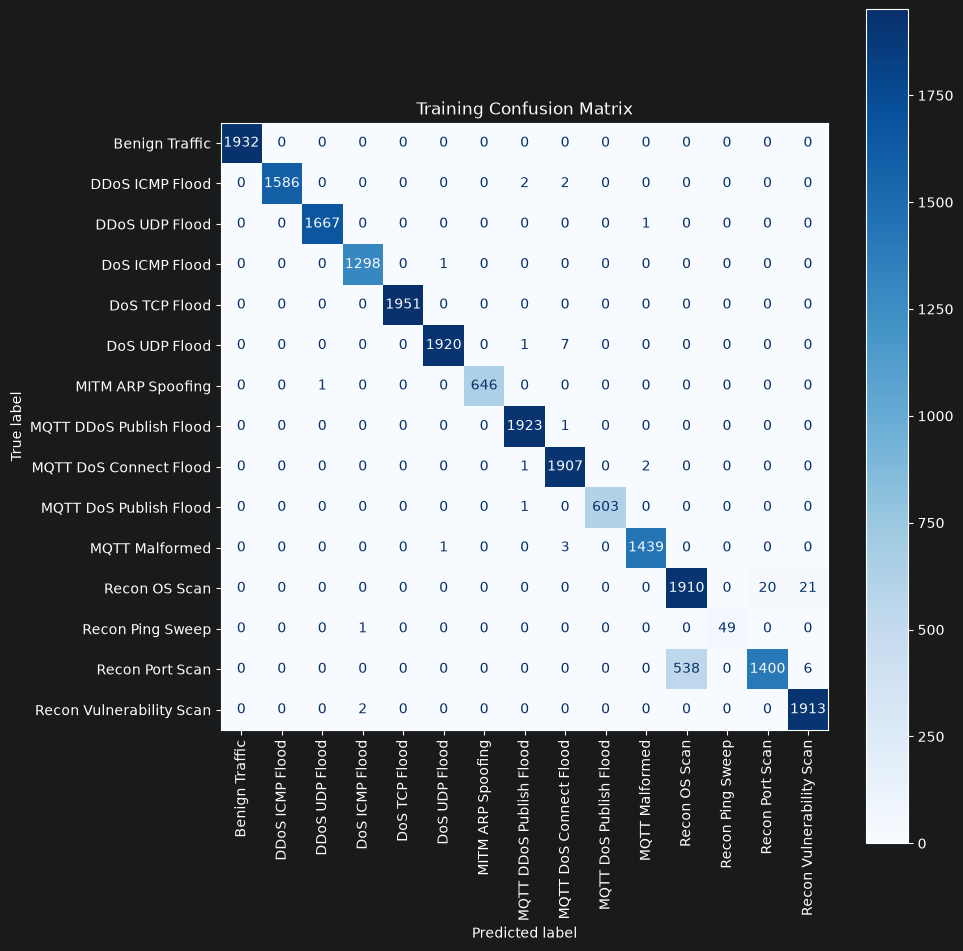

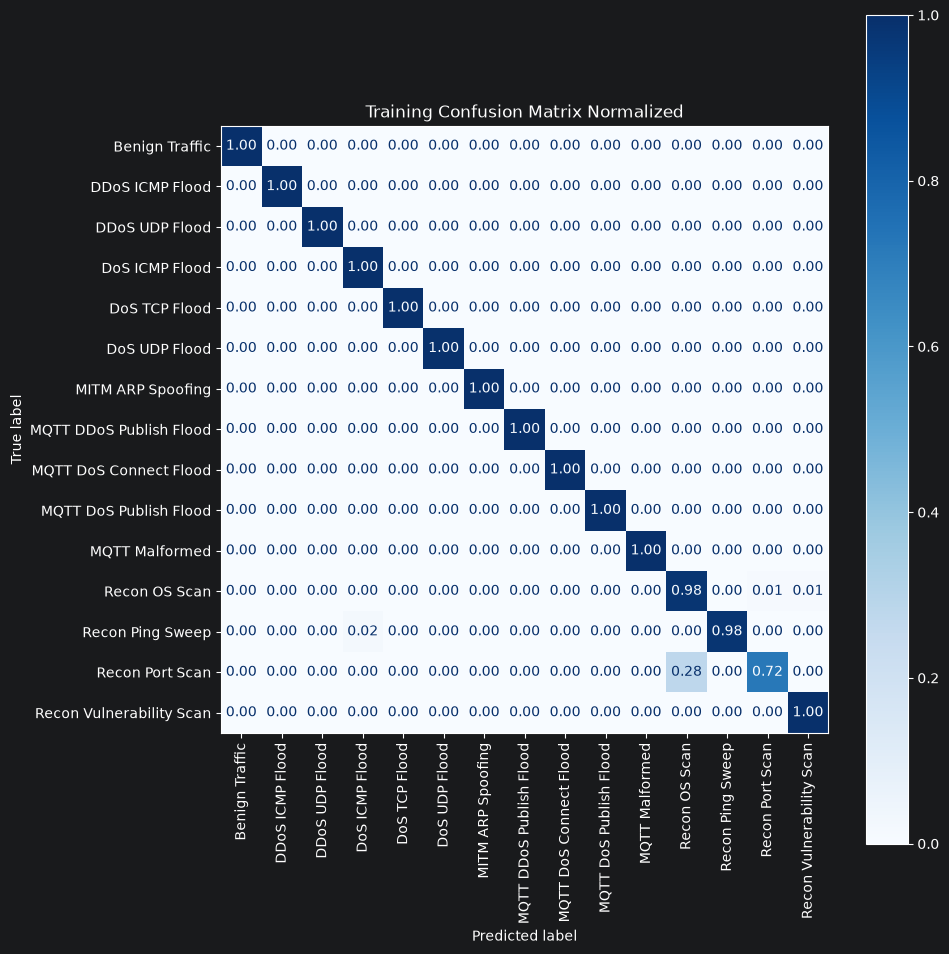

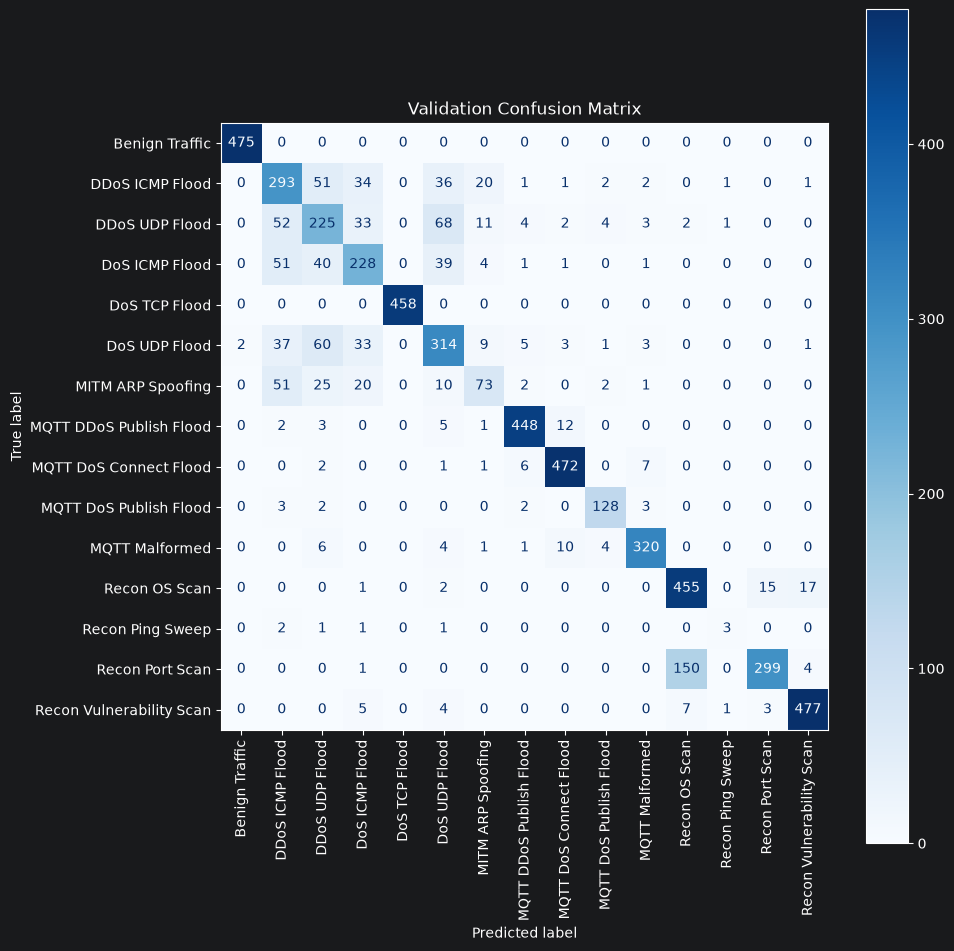

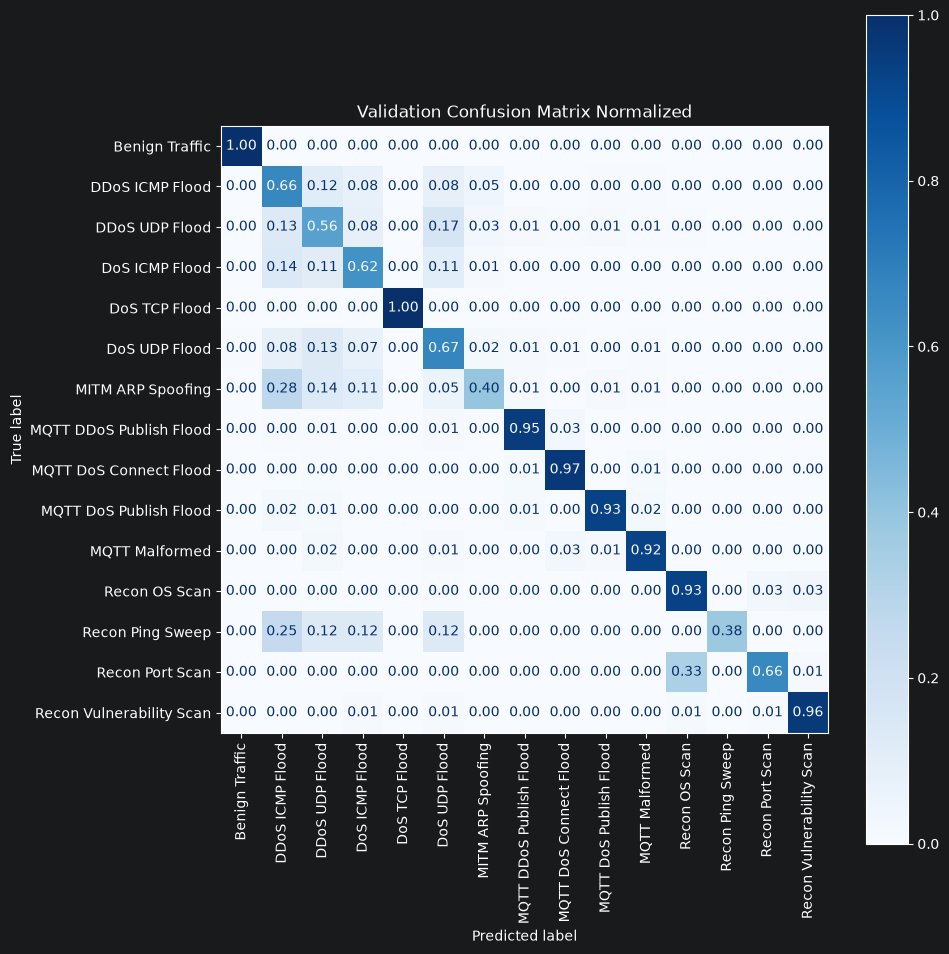

In [33]:
train_cm = plot_confusion_matrix(
    model_holdout,
    X_train,
    Y_train,
    title="Training Confusion Matrix"
)

train_cm_norm = plot_confusion_matrix_norm(
    model_holdout,
    X_train,
    Y_train,
    title="Training Confusion Matrix Normalized"
)

val_cm = plot_confusion_matrix(
    model_holdout,
    X_val,
    Y_val,
    title="Validation Confusion Matrix"
)

val_cm_norm = plot_confusion_matrix_norm(
    model_holdout,
    X_val,
    Y_val,
    title="Validation Confusion Matrix Normalized"
)

### 6. Model Training - Stratified K-fold Cross-validation

##### 6a. Heading

In [48]:
k = 10
strat_kfold = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

model_cv = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier())
])

scoring = {
    "accuracy": "accuracy",
    "precision_weighted": "precision_weighted",
    "recall_weighted": "recall_weighted",
    "f1_weighted": "f1_weighted",
    "f1_macro": "f1_macro",
}

cv_results = cross_validate(
    model_cv,
    features_train,
    targets_train,
    cv=strat_kfold,
    scoring=scoring,
    return_train_score=True
)
cv_results

{'fit_time': array([4.15206027, 3.97304082, 4.2251122 , 3.97259688, 3.90810108,
        4.07161593, 3.91617203, 4.11130118, 4.1560142 , 3.8640182 ]),
 'score_time': array([0.07288694, 0.06571102, 0.07426691, 0.06642008, 0.06502414,
        0.06739902, 0.06615114, 0.06509995, 0.0658989 , 0.06509399]),
 'test_accuracy': array([0.83514938, 0.83690685, 0.82390158, 0.82038664, 0.82811951,
        0.8228471 , 0.83438819, 0.82348805, 0.82770745, 0.83438819]),
 'train_accuracy': array([0.97398539, 0.97394633, 0.97371196, 0.97425882, 0.97293074,
        0.97300887, 0.97242403, 0.97176002, 0.9745723 , 0.97289274]),
 'test_precision_weighted': array([0.83910814, 0.84280919, 0.82926513, 0.82683679, 0.83322378,
        0.83010008, 0.84102949, 0.82886138, 0.83218395, 0.83799115]),
 'train_precision_weighted': array([0.97788624, 0.97768231, 0.97771734, 0.97819434, 0.97712005,
        0.97718998, 0.97672306, 0.97634844, 0.97833668, 0.97706539]),
 'test_recall_weighted': array([0.83514938, 0.83690685, 

##### 6b. Dataframe for summarizing results

In [44]:
cv_scores = pandas.DataFrame({
    metric: {
        "Mean": cv_results[f"test_{metric}"].mean(),
        "Std": cv_results[f"test_{metric}"].std()
    }
    for metric in scoring
}).T
cv_scores.round(4)

,Mean,Std
accuracy,0.8284,0.0064
precision_weighted,0.8341,0.0062
recall_weighted,0.8284,0.0064
f1_weighted,0.8274,0.0066
f1_macro,0.7904,0.0110


##### 6c. Training and Validation Comparison

In [45]:
cv_comparison = pandas.DataFrame({
    "Train Mean": [
        cv_results[f"train_{metric}"].mean()
        for metric in scoring
    ],
    "Train Std": [
        cv_results[f"train_{metric}"].std()
        for metric in scoring
    ],
    "Validation Mean": [
        cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Validation Std": [
        cv_results[f"test_{metric}"].std()
        for metric in scoring
    ],

}, index=scoring.keys())

cv_comparison["Mean Gap"] = (cv_comparison["Train Mean"] - cv_comparison["Validation Mean"])

cv_comparison.round(4)

,Train Mean,Train Std,Validation Mean,Validation Std,Mean Gap
accuracy,0.9734,0.0009,0.8284,0.0064,0.1449
precision_weighted,0.9774,0.0007,0.8341,0.0062,0.1434
recall_weighted,0.9734,0.0009,0.8284,0.0064,0.1449
f1_weighted,0.9729,0.0010,0.8274,0.0066,0.1455
f1_macro,0.9774,0.0009,0.7904,0.0110,0.1869
